## imports


In [1]:
import os
import sys
import matplotlib.pyplot as plt
import torch
import json


from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from mne_connectivity import spectral_connectivity_time

import warnings
warnings.filterwarnings("ignore", message="Using padding='same'", category=UserWarning)

In [2]:
dir_base = Path("../..")
print(os.path.abspath(dir_base))

sys.path.append(os.path.abspath(dir_base))


c:\Users\grabn\Documents\CGV_2024\xeegVis_alll\EEGlas_Seminararbeit\all-in-on-eeg


In [3]:
%load_ext autoreload
%autoreload 2

from shallownetXAI_main.AllFnc.models import ShallowNet, ShallowNet2
from shallownetXAI_main.AllFnc.training import lossBinary, lossMulti, train_model, get_performances

from backend.ml.data_utils.load_data import *
from backend.ml.data_utils.prepare_data import *
from backend.ml.xeegnet_scc_utils.xeegnet_with_conn import xEEGNetSCC, BANDS
from backend.ml.xeegnet_scc_utils.model_evaluations import *


from backend.ml.model_vars import PRETRAINED_MODEL_DIR
from backend.ml.train import train_save_model, get_train_val_test_loader, PARAMETERS_DEFAULT, TRAINING_PARAMETERS_DEFAULT, save_model, load_model_weights
from main import load_participant_splits

from backend.ml.scc_cache import SCCStore, SCCParams, build_x_y_scc, CachedSCCDataset, SCCReducer, pairs_to_dense

import mne


import selfeeg

c:\Users\grabn\Documents\CGV_2024\xeegVis_alll\EEGlas_Seminararbeit\all-in-on-eeg\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Read Data


#### paths


In [4]:
dir_data = os.path.join(dir_base, "data", "datasets", "ds004504")
dir_data_abs = os.path.abspath(dir_data)
data_path = os.path.join(dir_data, "sub-001", "eeg", "sub-001_task-eyesclosed_eeg.set")

dir_data_outer = os.path.join(dir_base, "data")

dir_shallownetXAI = os.path.join(
    dir_base, "backend", "experiments_xeegnet", "shallownetXAI_main"
)

# data_path = os.path.join(dir_data_abs, 'ds004504/sub-001/eeg/sub-001_task-eyesclosed_eeg.set')

dir_base_outer = Path("../../../")
DIR_FIGUREs_THESIS = dir_base_outer / "Seminararbeit" / "Figures" / "scc_generated"

## Settings


In [5]:
n_max = 1000
model_version = 200

### Metadata / y


In [6]:
df_metadata = load_metadata(dir_data=dir_data)


In [7]:
participant_ids = [1, 2, 3, 4, 5, 6, 40, 41, 42, 43, 44, 45, 80, 81, 82, 83, 84, 85]

df_eeg_small = load_multiple_eegfiles(
    dir_data=dir_data,
    participant_ids=participant_ids,  # , 43
    gen_path_func=gen_filename,
    df_metadata=df_metadata,
    # n_max=150,
)

Total memory usage of combined df_eeg: 146.56 MB


In [8]:
print(df_eeg_small.shape)
print(df_eeg_small.shape[0]/500)

df_eeg_small

(1746303, 22)
3492.606


,time,Fp1,Fp2,F3,F4,C3,C4,P3,P4,O1,...,F8,T3,T4,T5,T6,Fz,Cz,Pz,participant_id,diagnosis
0,0.000000,-216.707306,-154.500626,-115.910667,18.374157,-119.257698,-46.773888,-83.129326,163.208298,149.883255,...,-126.152870,-70.800987,-22.987829,-77.447159,-142.291214,-113.576492,-28.376854,-136.401978,sub-001,1
1,0.008000,-163.077789,-129.190735,-98.835381,38.559467,-97.636795,-26.175304,-64.038612,183.764389,149.042557,...,-98.163490,-47.460701,-1.328547,-79.095764,-120.501694,-92.966438,-8.048896,-117.015953,sub-001,1
2,0.016000,-172.030151,-130.024796,-112.606117,41.594624,-101.570793,-23.207067,-66.826469,184.497833,149.262833,...,-101.406677,-52.894779,-4.642946,-81.475250,-121.560654,-93.725876,-7.764234,-115.192619,sub-001,1
3,0.024000,-180.445724,-130.554886,-110.314621,38.854797,-102.682266,-25.941097,-68.745064,182.075104,152.322067,...,-98.266495,-51.201221,-5.227331,-77.432365,-124.645004,-95.773582,-8.484701,-119.355888,sub-001,1
4,0.032000,-171.958725,-123.986397,-102.452408,47.651417,-96.679337,-18.863199,-62.647579,188.566895,151.180359,...,-92.241425,-50.356083,7.061250,-78.966293,-115.325089,-85.054092,-3.320512,-112.621025,sub-001,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1746298,566.056030,-334.778961,-461.080200,-12.392676,-109.115646,-27.116936,3.937190,33.349224,186.175232,16.907085,...,523.421509,-74.546844,-145.072128,8.138496,79.886765,-165.247513,-119.598671,-26.595516,sub-085,2
1746299,566.064026,-331.106476,-443.040100,-9.627316,-86.885559,-27.830322,16.938120,23.238390,186.557190,-2.650816,...,518.816833,-75.742279,-135.133026,-10.951662,77.849358,-153.075699,-115.746742,-26.270397,sub-085,2
1746300,566.072021,-317.145325,-453.130127,-33.214951,-93.896927,-34.994781,14.072788,30.271244,187.258713,12.851168,...,520.202454,-79.579941,-137.797043,-1.603775,80.174294,-158.676422,-114.246872,-25.178518,sub-085,2
1746301,566.080017,-345.806946,-466.250427,-44.117954,-105.883453,-40.661743,2.022275,14.335395,171.554123,-11.031007,...,483.368561,-80.817986,-152.852478,-15.989891,63.558945,-174.053879,-132.624603,-41.565300,sub-085,2


### Calculate spectral connectivity


In [9]:

fmin = tuple(lo for lo, hi in BANDS.values())
fmax = tuple(hi for lo, hi in BANDS.values())

freqs = np.arange(1.0, 45.5, 1.0)  # 1..45 Hz in 1 Hz steps'
n_cycles = freqs / 2.0

In [10]:
subject = "sub-007"

data_path = os.path.join(
    dir_data, "derivatives", subject, "eeg", f"{subject}_task-eyesclosed_eeg.set"
)
eeg_data = load_preprocessed_raw_from_file(data_path)

In [11]:
sfreq = eeg_data.info["sfreq"]
window_sec = 4.0
epochs = mne.make_fixed_length_epochs(
    eeg_data, duration=window_sec, overlap=0.0, preload=True, verbose="ERROR"
)

window_index = 0
one_epoch = epochs[window_index]  # shape (1, n_channels, n_times)

In [12]:
con = spectral_connectivity_time(
    one_epoch,
    freqs=freqs,
    method="coh",
    mode="cwt_morlet",
    n_cycles=n_cycles,
    fmin=fmin,
    fmax=fmax,
    faverage=True,  # average within each band -> one value per band
    average=False,  # keep per-epoch (we only have 1 epoch anyway)
    sfreq=sfreq,
    verbose="ERROR",
)

In [13]:
# con.get_data() shape: (n_epochs, n_connections, n_bands)
# n_connections = n_channels**2 (flattened full matrix, most entries are the lower triangle)
data = con.get_data()  # (1, C*C, 5)
print(data.shape)

(1, 361, 7)


### visualize spectral connectivity


In [14]:
n_ch = len(one_epoch.ch_names)
# spectral_connectivity_time returns the full C*C flattened; reshape to (C, C, n_bands)
conn_matrix = data[0].reshape(n_ch, n_ch, len(BANDS))  # [X, Y, band]

# To reproduce DICE's SCC_x (eq. 4): average each channel's coherence with all others.
# DICE did: SCC_x = (1/C) * sum_y coherence(x,y)  -> collapses the Y axis -> one scalar per channel.
# Note: the connectivity matrix is lower-triangular (upper half is zeros); symmetrize first.
conn_sym = conn_matrix + np.transpose(conn_matrix, (1, 0, 2))  # mirror lower->upper
scc_per_channel = conn_sym.mean(axis=1)  # [C, band] -> DICE's per-channel SCC feature

print(f"shape of SCC per channel: {scc_per_channel.shape} (n_channels, n_bands)")

shape of SCC per channel: (19, 7) (n_channels, n_bands)


In [15]:

LABEL_SIZE = 15   # tick labels + value annotations
TITLE_SIZE = 15   # band names
plt.rcParams.update({
    "font.size": LABEL_SIZE,        # baseline for everything
    "axes.titlesize": TITLE_SIZE,   # band names
    "axes.labelsize": LABEL_SIZE,   # "mean coherence"
    "xtick.labelsize": LABEL_SIZE,   # channel names in the edge matrix
    "ytick.labelsize": LABEL_SIZE,
})

In [21]:
# set labelsize
plt.rcParams.update({'font.size': 12})

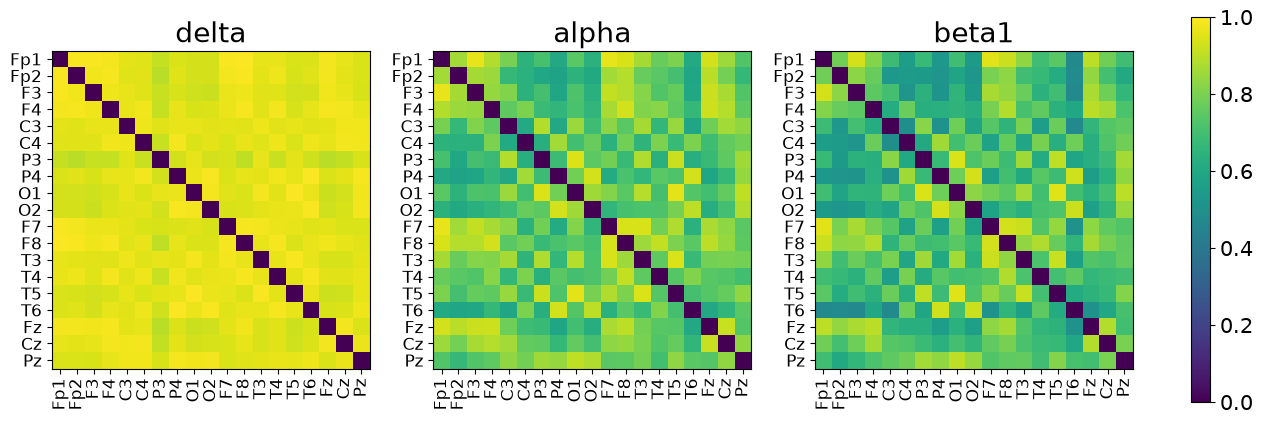

In [ ]:
# reducer mode edge, full 19x19 connectivity matrix per band

bands_to_show = ["delta", "alpha", "beta1"]

ch_names = one_epoch.ch_names
band_names = list(BANDS.keys())
band_indices = {band: i for i, band in enumerate(band_names)}

fontsize_title = 20
tick_labelsize = 12
panel_size = 5   # inches per matrix, controls the size of each single matrix

fig, axes = plt.subplots(1, len(bands_to_show), figsize=(1 * panel_size * len(bands_to_show), 1 * panel_size))
if len(bands_to_show) == 1:
    axes = [axes]

for ax, band in zip(axes, bands_to_show):
    b = band_indices[band]
    ax.set_title(band, fontsize=fontsize_title)
    im = ax.imshow(conn_sym[:, :, b], vmin=0, vmax=1, cmap="viridis")
    ax.set_title(band, fontsize=fontsize_title)
    ax.set_xticks(range(len(ch_names)))
    ax.set_yticks(range(len(ch_names)))
    ax.set_xticklabels(ch_names, rotation=90, fontsize=tick_labelsize)
    ax.set_yticklabels(ch_names, fontsize=tick_labelsize)
fig.colorbar(im, ax=axes, fraction=0.02)

fig_name = f"scc_matrix_{subject}_window{window_index}.pdf"
fig_path = DIR_FIGUREs_THESIS / fig_name
# fig.savefig(fig_path, dpi=300, bbox_inches="tight")

# Seminararbeit\Figures\scc_generated\scc_matrix_sub-007_window0.pdf

# fig.savefig(r"Seminararbeit\Figures\scc_generated\scc_matrix_sub-007_window0.pdf", dpi=300, bbox_inches="tight")

plt.show()

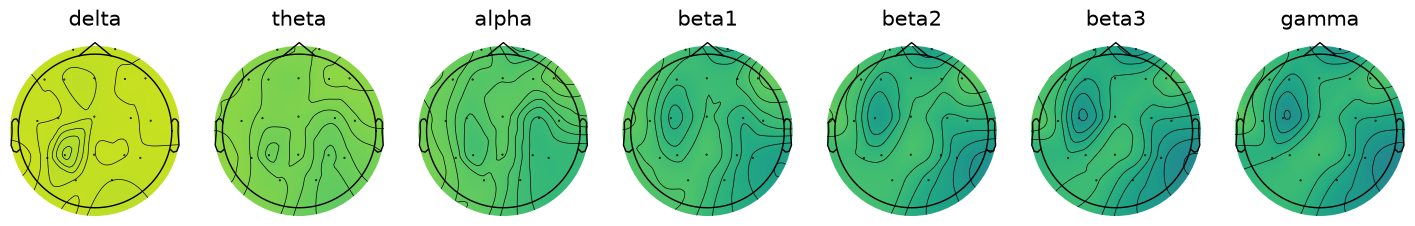

In [17]:
# reducer mode node, average connectivity per channel per band

one_epoch.set_montage("standard_1020", on_missing="warn")

fig, axes = plt.subplots(1, len(band_names), figsize=(18, 4))
for b, (ax, band) in enumerate(zip(axes, band_names)):
    mne.viz.plot_topomap(
        scc_per_channel[:, b],
        one_epoch.info,
        axes=ax,
        show=False,
        vlim=(0, 1),
        cmap="viridis",
    )
    ax.set_title(band)

fig_name = f"scc_per_channel_{subject}_window{window_index}.pdf"
fig_path = DIR_FIGUREs_THESIS / fig_name
fig.savefig(fig_path, dpi=300, bbox_inches="tight")

plt.show()

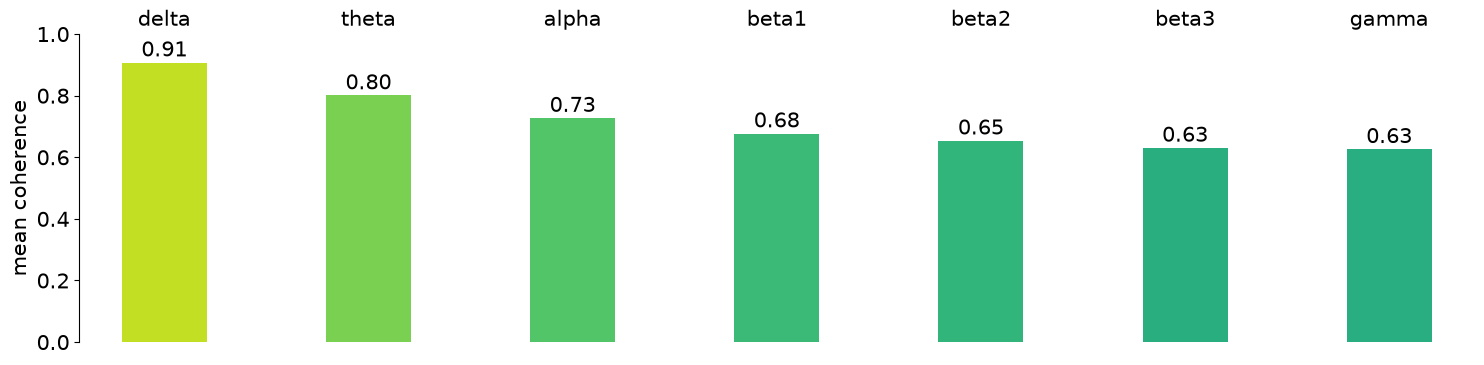

In [18]:
# reducer mode mean, average connectivity across all channels and per band


scc_mean_per_band = scc_per_channel.mean(axis=0)  # (n_bands,)
cmap = plt.get_cmap("viridis")



fig, axes = plt.subplots(1, len(band_names), figsize=(18, 4), sharey=True)
for ax, band, value in zip(axes, band_names, scc_mean_per_band):
    ax.bar([0], [value], width=0.6, color=cmap(value))
    ax.set_title(band)
    ax.set_ylim(0, 1)
    ax.set_xlim(-0.6, 0.6)
    ax.set_xticks([])
    # ax.set_yticks([])
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    # ax.tick_params(axis="x", labelsize=LABEL_SIZE)
    ax.text(0, value + 0.02, f"{value:.2f}", ha="center", fontsize=LABEL_SIZE)

axes[0].set_ylabel("mean coherence")
for ax in axes[1:]:
    ax.spines["left"].set_visible(False)
    ax.tick_params(left=False)

# axes[0].set_ylabel("mean coherence", fontsize=LABEL_SIZE)
# axes[0].tick_params(axis="y", labelsize=LABEL_SIZE)

fig_name = f"scc_mean_per_band_{subject}_window{window_index}.pdf"
fig_path = DIR_FIGUREs_THESIS / fig_name
plt.savefig(fig_path, dpi=300, bbox_inches="tight")

plt.show()

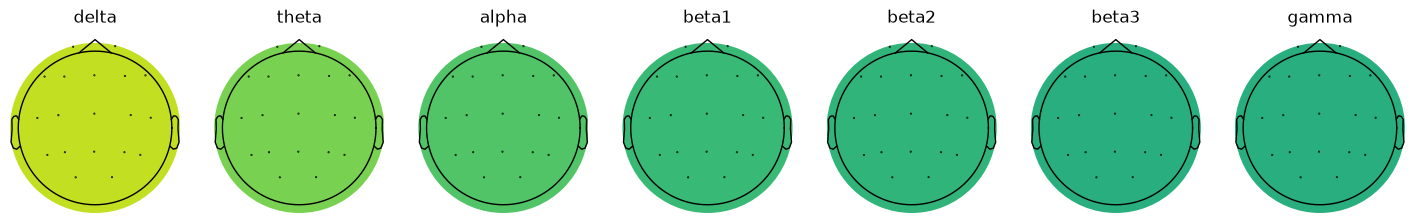

In [39]:
# reducer mode mean, average connectivity across all channels and per band

one_epoch.set_montage("standard_1020", on_missing="warn")

fig, axes = plt.subplots(1, len(band_names), figsize=(18, 4))
for b, (ax, band) in enumerate(zip(axes, band_names)):
    mne.viz.plot_topomap(
        scc_per_channel[:, b].mean() + np.zeros_like(scc_per_channel[:, b]),  # add a constant to make it a 1D array of the same shape
        one_epoch.info,
        axes=ax,
        show=False,
        vlim=(0, 1),
        cmap="viridis",
    )
    ax.set_title(band)
plt.show()

In [28]:
scc_per_channel[:, b].mean()

np.float64(0.6262590843952819)

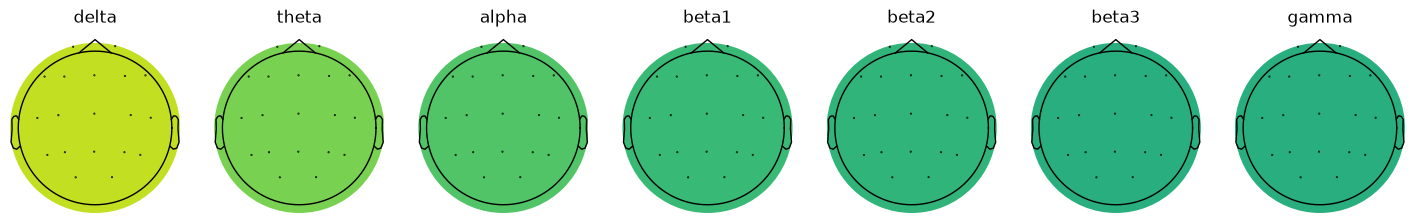

In [32]:
one_epoch.set_montage("standard_1020", on_missing="warn")

fig, axes = plt.subplots(1, len(band_names), figsize=(18, 4))
for b, (ax, band) in enumerate(zip(axes, band_names)):
    mne.viz.plot_topomap(
        scc_per_channel[:, b].mean() + np.zeros_like(scc_per_channel[:, b]),  # add a constant to make it a 1D array of the same shape
        one_epoch.info,
        axes=ax,
        show=False,
        vlim=(0, 1),
        cmap="viridis",
    )
    ax.set_title(band)
plt.show()

In [34]:
band_names

['delta', 'theta', 'alpha', 'beta1', 'beta2', 'beta3', 'gamma']

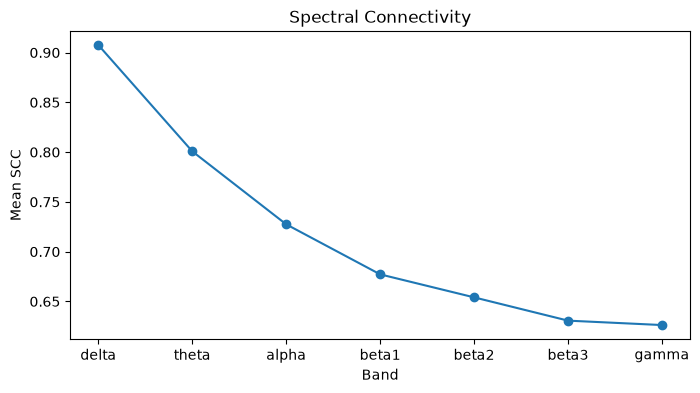

In [33]:
# create line plot of mean scc (across channels) for each band
mean_scc_per_band = scc_per_channel.mean(axis=0)  # mean across channels

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(band_names, mean_scc_per_band, marker='o')
plt.xlabel('Band')
plt.ylabel('Mean SCC')
plt.title('Spectral Connectivity')
plt.show()



# use precomputed scc

In [82]:
df_metadata

,participant_id,Gender,Age,Group,MMSE,group_long,group_encoded,participant_id_int
0,sub-001,F,57,A,16,Alzheimer Disease Group,1,1
1,sub-002,F,78,A,22,Alzheimer Disease Group,1,2
2,sub-003,M,70,A,14,Alzheimer Disease Group,1,3
3,sub-004,F,67,A,20,Alzheimer Disease Group,1,4
4,sub-005,M,70,A,22,Alzheimer Disease Group,1,5
...,...,...,...,...,...,...,...,...
83,sub-084,F,71,F,24,Frontotemporal Dementia Group,2,84
84,sub-085,M,64,F,26,Frontotemporal Dementia Group,2,85
85,sub-086,M,49,F,26,Frontotemporal Dementia Group,2,86
86,sub-087,M,73,F,24,Frontotemporal Dementia Group,2,87


In [79]:
window = 4
verbose = True

# lossVal = None
seed = 83136297

downsample = True
Chans = 19
srate = 125 if downsample else 250

sample_length = 125 * 4  # srate * window

In [80]:
path=Path(dir_data_outer) / "scc_cache" / "ds004504" / "derivatives" 

store  = SCCStore(
    root=Path(dir_data_outer) / "scc_cache" 
)
scc_params = SCCParams.default(sfreq=srate, sample_length=sample_length)

In [99]:
source = "derivatives"
dataset_id = "ds004504"

participant_ids = np.arange(1, 88)

label_of = {
    f"sub-{int(r.participant_id.split('-')[1]):03d}": int(r.group_encoded)
    for r in df_metadata.itertuples()
}

x, y, scc, data_subject_ids = build_x_y_scc(
    dir_data=dir_data,
    participant_ids=participant_ids,
    label_of_subject=label_of,
    store=store,
    params=scc_params,
    load_model_windows_for_participant=load_model_windows_for_participant,
    dataset_id=dataset_id,
    n_channels=Chans,
    source=source,
    sample_length=sample_length,
    n_jobs=1,
    print_info=True,
)

data_x_y_scc_id = (x, y, scc, data_subject_ids)
# data_x_y_id = (x, y, data_subject_ids)

  cache hit for sub-001 (derivatives) -> (149, 7, 171)
  cache hit for sub-002 (derivatives) -> (198, 7, 171)
  cache hit for sub-003 (derivatives) -> (76, 7, 171)
  cache hit for sub-004 (derivatives) -> (176, 7, 171)
  cache hit for sub-005 (derivatives) -> (201, 7, 171)
  cache hit for sub-006 (derivatives) -> (158, 7, 171)
  cache hit for sub-007 (derivatives) -> (191, 7, 171)
  cache hit for sub-008 (derivatives) -> (198, 7, 171)
  cache hit for sub-009 (derivatives) -> (153, 7, 171)
  cache hit for sub-010 (derivatives) -> (320, 7, 171)
  cache hit for sub-011 (derivatives) -> (192, 7, 171)
  cache hit for sub-012 (derivatives) -> (220, 7, 171)
  cache hit for sub-013 (derivatives) -> (209, 7, 171)
  cache hit for sub-014 (derivatives) -> (233, 7, 171)
  cache hit for sub-015 (derivatives) -> (225, 7, 171)
  cache hit for sub-016 (derivatives) -> (243, 7, 171)
  cache hit for sub-017 (derivatives) -> (210, 7, 171)
  cache hit for sub-018 (derivatives) -> (211, 7, 171)
  cache hit

## Visualize

In [111]:
import numpy as np
import matplotlib.pyplot as plt
from backend.ml.scc_cache import SCCStore, SCCParams, build_x_y_scc, CachedSCCDataset, SCCReducer, pairs_to_dense

x, y, scc, data_subject_ids = data_x_y_scc_id   # scc: (N, 7, 171), y: (N,), sids: (N,)

n_channels = Chans          # 19
band_names = ["delta", "theta", "alpha", "beta1", "beta2", "beta3", "gamma"]
group_names = {0: "CN (healthy)", 1: "AD", 2: "FTD"}   # your group_encoded mapping

def scc_mean_per_band_per_window(scc_block):
    """(M, 7, 171) -> (M, 7): mean off-diagonal coherence per band, per window.
    Rebuild 19x19, mean over the C-1 other channels, then over channels."""
    dense = pairs_to_dense(scc_block, n_channels, fill_diagonal=0.0)   # (M, 7, C, C)
    per_channel = dense.sum(axis=-1) / (n_channels - 1)                # (M, 7, C)
    return per_channel.mean(axis=-1)                                   # (M, 7)

# per-band mean for every window, then aggregate per subject, then per group
per_window = scc_mean_per_band_per_window(scc)        # (N, 7)

group_means = {}
for g in group_names:
    subj_in_group = [s for s in np.unique(data_subject_ids)
                     if y[data_subject_ids == s][0] == g]
    # subject-level mean first (equal weight per patient), then average subjects
    subj_means = np.stack([per_window[data_subject_ids == s].mean(0)
                           for s in subj_in_group])    # (n_subjects_in_group, 7)
    group_means[g] = subj_means.mean(0)                # (7,)
    print(f"{group_names[g]}: {len(subj_in_group)} subjects, {(y == g).sum()} windows")

CN (healthy): 29 subjects, 6015 windows
AD: 36 subjects, 7267 windows
FTD: 22 subjects, 3941 windows


In [124]:
if False:
    LABEL_SIZE = 10
    cmap = plt.get_cmap("viridis")

    fig, axes = plt.subplots(3, len(band_names), figsize=(18, 10),
                            sharey=True, sharex=True)

    for row, g in enumerate(group_names):
        vals = group_means[g]
        for col, (band, value) in enumerate(zip(band_names, vals)):
            ax = axes[row, col]
            ax.bar([0], [value], width=0.6, color=cmap(value))
            ax.set_ylim(0, 1); ax.set_xlim(-0.6, 0.6); ax.set_xticks([])
            ax.spines[["top", "right", "bottom"]].set_visible(False)
            ax.text(0, value + 0.02, f"{value:.2f}", ha="center", fontsize=LABEL_SIZE)
            if row == 0:
                ax.set_title(band)
            if col == 0:
                ax.set_ylabel(f"{group_names[g]}\nmean coherence")
            else:
                ax.spines["left"].set_visible(False)
                ax.tick_params(left=False)

    plt.tight_layout()
    plt.show()

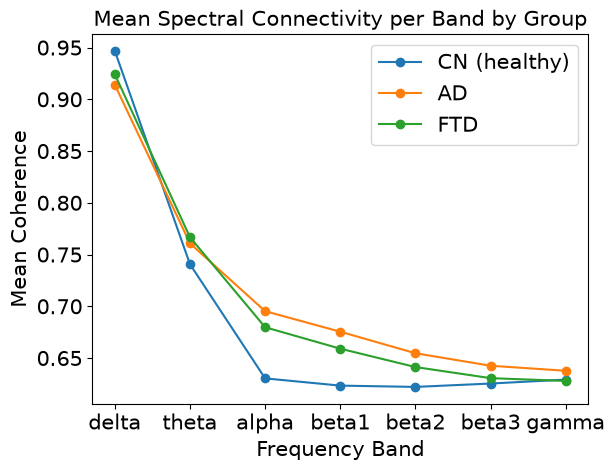

In [127]:
# plot all three groups in one plot, with different colors for each group
for row, g in enumerate(group_names):
    vals = group_means[g]
    plt.plot(band_names, vals, marker='o', label=group_names[g])
    plt.xlabel("Frequency Band")
    plt.ylabel("Mean Coherence")
    plt.title("Mean Spectral Connectivity per Band by Group")

#legend
plt.legend()


# save figure to Seminararbeit\Figures\scc_generated

fig_name = "scc_mean_per_band_by_group.pdf"
fig_path = os.path.join(DIR_FIGUREs_THESIS, fig_name)


plt.savefig(fig_path, bbox_inches='tight')

In [115]:
def scc_per_channel_per_window(scc_block):
    """(M, 7, 171) -> (M, 7, C): mean off-diagonal coherence of each channel
    with all others, per band, per window."""
    dense = pairs_to_dense(scc_block, n_channels, fill_diagonal=0.0)   # (M, 7, C, C)
    return dense.sum(axis=-1) / (n_channels - 1)                       # (M, 7, C)

per_window_ch = scc_per_channel_per_window(scc)     # (N, 7, C)

group_ch_means = {}
for g in group_names:
    subj_in_group = [s for s in np.unique(data_subject_ids)
                     if y[data_subject_ids == s][0] == g]
    subj_means = np.stack([per_window_ch[data_subject_ids == s].mean(0)
                           for s in subj_in_group])   # (n_subj, 7, C)
    group_ch_means[g] = subj_means.mean(0)            # (7, C)

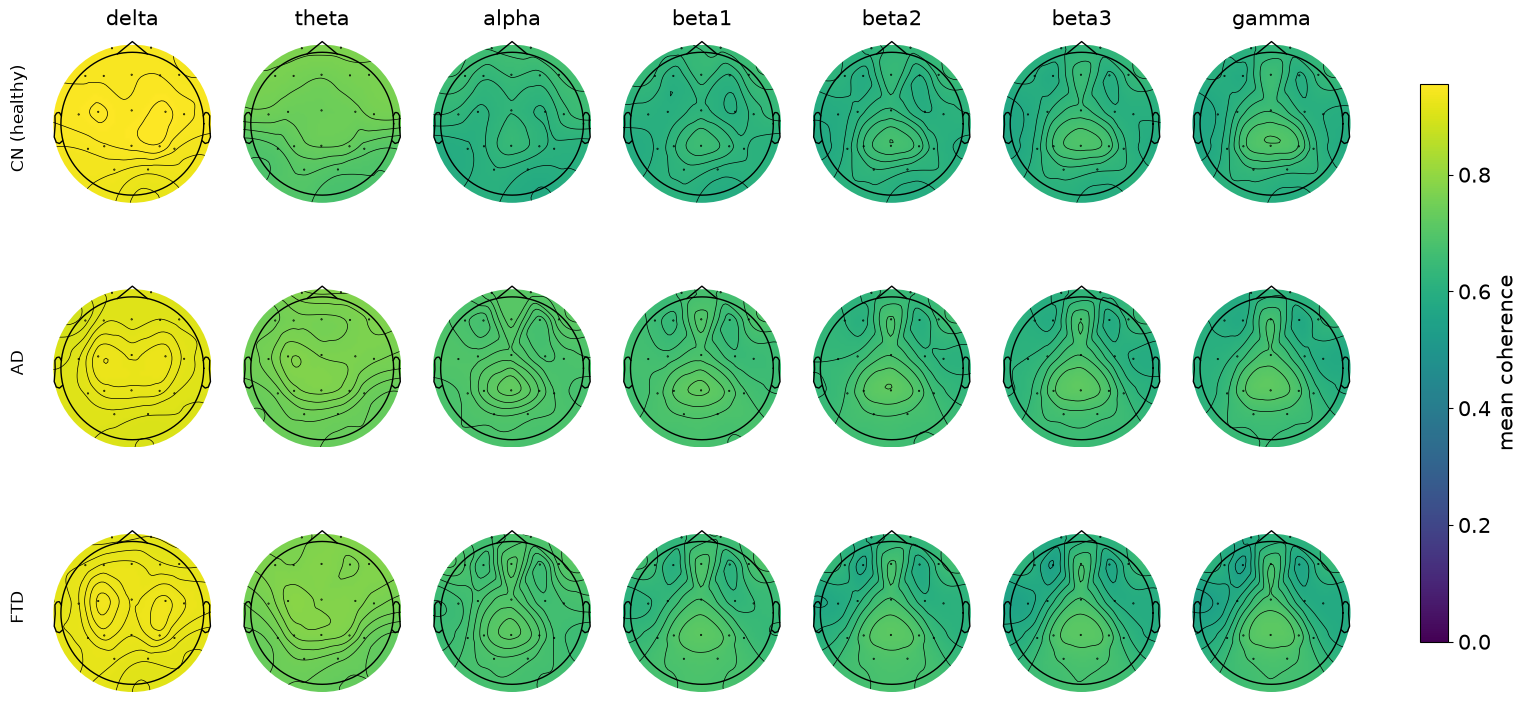

In [117]:
import mne

# Build a 19-channel info with the 10-20 montage, matching your channel order.
# MODEL_CHANNELS is your fixed channel order; if you don't have it, use one_epoch.info directly.
info = one_epoch.info   # already has the montage set from your snippet

# Shared colour scale across all groups/bands so rows are comparable.
vmax = max(group_ch_means[g].max() for g in group_names)

fig, axes = plt.subplots(3, len(band_names), figsize=(18, 9))
im = None
for row, g in enumerate(group_names):
    ch_means = group_ch_means[g]                       # (7, C)
    for col, band in enumerate(band_names):
        ax = axes[row, col]
        im, _ = mne.viz.plot_topomap(
            ch_means[col],                             # (C,) for this band
            info,
            axes=ax,
            show=False,
            vlim=(0, vmax),
            cmap="viridis",
        )
        if row == 0:
            ax.set_title(band)
    axes[row, 0].set_ylabel(group_names[g], rotation=90,
                            labelpad=25, fontsize=12, va="center")

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, label="mean coherence")
plt.show()

## self eeg with conn


In [ ]:
def build_xeegnet_scc(nb_classes=3, Chans=19, Samples=125 * 4, Fs=125):
    base = selfeeg.models.xEEGNet(
        nb_classes=3,
        Chans=19,
        Samples=125 * 4,
        Fs=125,
        global_pooling=True,
    )
    # Wrapper with cached spectral connectivity pairs
    xeegnet_scc = xEEGNetSCC(base_model=base, reducer_mode_scc="mean")
    return xeegnet_scc

In [ ]:
# Base xEEGNet
base = selfeeg.models.xEEGNet(
    nb_classes=3,
    Chans=19,
    Samples=125 * 4,
    Fs=125,
    global_pooling=True,
 )
# Wrapper with cached spectral connectivity pairs
xeegnet_scc = xEEGNetSCC(base_model=base, reducer_mode_scc="mean")

# # Smoke test input: (batch, channels, samples) plus cached SCC pairs
# torch.manual_seed(42)
# x = torch.randn(2, 19, 125 * 4)
# scc_pairs = torch.as_tensor(cached_scc[:2], dtype=torch.float32)
# out = xeegnet_scc([x, scc_pairs])

# print("input shape:", x.shape)
# print("scc shape:", scc_pairs.shape)
# print("output shape:", out.shape)
# print("contains NaN:", torch.isnan(out).any().item())
# out

In [23]:
torch.manual_seed(42)
out = base(torch.randn(2, 19, 125 * 4))
out

tensor([[-0.0255, -0.0097,  0.0611],
        [ 0.0246,  0.2963, -0.5202]], grad_fn=<MmBackward0>)

# test models


#### settings


In [24]:
pipelineToEval = "filt"  #'icasr'
taskToEval = "alzheimer"
modelToEval = "shallownet_custom"  # shallownet, shallownet_custom
outFold = 1
inFold = 5
downsample = True
z_score = True
rem_interp = True
batchsize = 64
overlap = 0.0
workers = 0
window = 4
verbose = True
lr = 5 * 10 ** (-5)
epochs = 1000
lossVal = None
arch_acronym = "shn7db"
seed = 83136297

In [25]:
nb_classes = 3
Chans = 19
srate = 125 if downsample else 250

sample_length = 125 * 4  # srate * window

In [26]:
# Med-ShallowNet
shallownet_custom_dict = {
    "F1": 7,
    "K1": 125,
    "F2": 7,
    "Pool": 75,
    "p": 0.2,
    "log_activation_base": "dB",
    "norm_type": "batchnorm",
    "random_temporal_filter": False,
    "Fs": 125 if downsample else 250,
    "freeze_temporal": 999999999,
    "dense_hidden": None,
    "spatial_depthwise": True,
    "spatial_only_positive": False,
    "global_pooling": True,
    "bias": [False, False, False],
    "return_logits": True,
    "seed": seed,
}

In [27]:
# SET DEVICE: 0 = ZANOLA
if torch.cuda.is_available():
    device = torch.device(0)
else:
    device = torch.device("cpu")
print(device)

cpu


### Generate models


In [28]:
# For selfEEG's models instantiation
sample_length = int(srate * window)
shallow_net_2 = ShallowNet2(
    nb_classes=nb_classes, Chans=Chans, Samples=sample_length, seed=seed
)
shallow_net = ShallowNet(
    nb_classes=nb_classes, Chans=Chans, Samples=sample_length, seed=seed
)

xeegnet = selfeeg.models.xEEGNet(
    nb_classes=nb_classes,
    Chans=Chans,
    Samples=sample_length,
    Fs=125 if downsample else 250,
    global_pooling=True,
)

#### Test forward pass


In [29]:
n_batches = 10

x = torch.randn(n_batches, Chans, sample_length, dtype=torch.float32)
scc_pairs = torch.randn(n_batches, len(BANDS), Chans*(Chans-1)//2, dtype=torch.float32)

out = xeegnet_scc([x, scc_pairs])
print(out.shape)  # shoud return torch.Size([3, 3])
print(torch.isnan(out).sum())  # shoud return 0
out

torch.Size([10, 3])
tensor(0)


tensor([[-1.5147,  0.6936, -1.3242],
        [-0.2141,  0.3363,  0.3734],
        [-0.3303,  0.4090,  0.5107],
        [ 0.8662, -0.0032,  1.1960],
        [ 0.1301, -0.0946, -1.2147],
        [ 1.2028, -0.0990,  0.1113],
        [ 0.6465, -0.1951,  0.2733],
        [ 0.6907,  0.5524,  1.6578],
        [-0.5335, -0.0566, -1.4199],
        [-0.4281, -0.3312,  0.4382]], grad_fn=<MmBackward0>)

In [30]:
def inference(model, x: torch.Tensor | np.ndarray):
    model.eval()

    if isinstance(x, np.ndarray):
        x = torch.from_numpy(x).float()
    with torch.no_grad():
        out = model(x)
    return out

In [31]:
# out = inference(xeegnet, x_input)
# print(out.shape)
# out

## calculating spectral connectivity cache


In [32]:
participant_ids = [2,3]

# 4 - 88
participant_ids = np.arange(1, 89).tolist()
print(participant_ids)
# participant_ids

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88]


In [ ]:
path=Path(dir_data_outer) / "scc_cache" / "ds004504" / "derivatives" 

store  = SCCStore(
    root=Path(dir_data_outer) / "scc_cache" 
)
params = SCCParams.default(sfreq=srate, sample_length=sample_length)

In [35]:
# #  # from backend.data.load_data import load_model_windows_for_participant, load_metadata

df   = load_metadata(dir_data)
label_of = {f"sub-{int(r.participant_id.split('-')[1]):03d}": int(r.group_encoded)
            for r in df.itertuples()}

# x, y, scc, sids = build_x_y_scc(
#     dir_data, participant_ids, label_of, store, params,
#     load_model_windows_for_participant,
#     dataset_id="ds004504", n_channels=Chans, source="derivatives",  
#     sample_length=sample_length,
# )

# train_ds = CachedSCCDataset(x, scc, y)  # yields ([x, scc], y)


## Load and visualize cached SCC

The cache stores raw pair vectors, not the full MNE connectivity object. Use `store.get(...)` to load a subject's cached array, then `pairs_to_dense(...)` to reconstruct a symmetric band-by-channel matrix for plotting.


In [36]:

dataset_id = "ds004504"
# subject_id = "sub-001"
subject_id = "sub-007"
source = "derivatives"

cached_scc = store.get(dataset_id, subject_id, source, params)
if cached_scc is None:
    raise FileNotFoundError(
        f"No cached SCC found for {subject_id}. Precompute the cache first or check params.key()."
    )

cache_json_path = store._json_path(dataset_id, subject_id, source, params.key())
cache_npy_path = store._npy_path(dataset_id, subject_id, source, params.key())
cache_meta = json.loads(cache_json_path.read_text(encoding="utf-8"))

print("cached_scc type:", type(cached_scc))
print("cached_scc dtype / shape:", cached_scc.dtype, cached_scc.shape)
print("sidecar type:", type(cache_meta))
print("sidecar keys:", sorted(cache_meta.keys()))
print("npy path:", cache_npy_path)
print("json path:", cache_json_path)

# One cached window is a raw pair tensor: (n_bands, n_pairs)
window_idx = 0
cached_window = cached_scc[window_idx]
print("one window type / shape:", type(cached_window), cached_window.shape)

cached_scc type: <class 'numpy.ndarray'>
cached_scc dtype / shape: float32 (191, 7, 171)
sidecar type: <class 'dict'>
sidecar keys: ['band_edges', 'band_names', 'created_at', 'dataset_id', 'method', 'mode', 'n_bands', 'n_channels', 'n_pairs', 'n_windows', 'pair_convention', 'sample_length', 'scc_cache_version', 'scc_key', 'sfreq', 'source', 'subject_id']
npy path: ..\..\data\scc_cache\ds004504\scc-f1c09c5a2124ee89\subjects\sub-007.derivatives.scc.npy
json path: ..\..\data\scc_cache\ds004504\scc-f1c09c5a2124ee89\subjects\sub-007.derivatives.scc.json
one window type / shape: <class 'numpy.ndarray'> (7, 171)


conn_dense shape: (7, 19, 19)


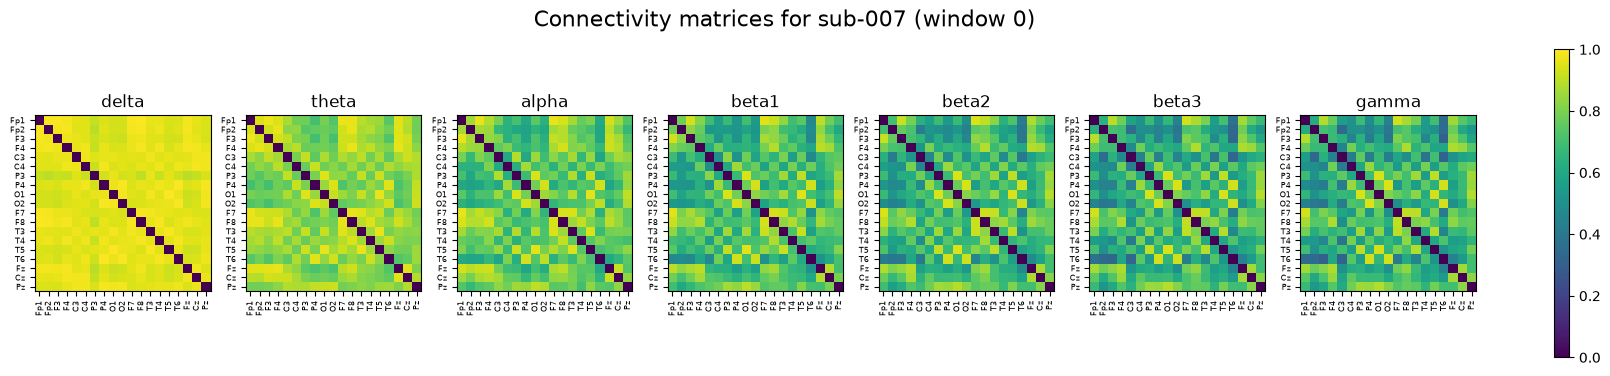

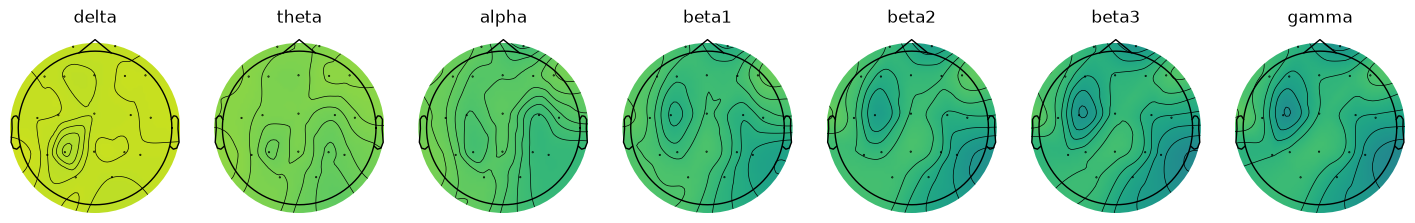

In [37]:
def plot_scc_window(conn_dense, subject_id=None, window_idx=None, one_epoch=None):
    band_names = list(BANDS.keys())

    fig, axes = plt.subplots(1, len(band_names), figsize=(20, 4))
    for b, (ax, band) in enumerate(zip(axes, band_names)):
        im = ax.imshow(conn_dense[b], vmin=0, vmax=1, cmap="viridis")
        ax.set_title(band)
        ax.set_xticks(range(len(one_epoch.ch_names)))
        ax.set_yticks(range(len(one_epoch.ch_names)))
        ax.set_xticklabels(one_epoch.ch_names, rotation=90, fontsize=6)
        ax.set_yticklabels(one_epoch.ch_names, fontsize=6)
    fig.colorbar(im, ax=axes, fraction=0.02)

    if subject_id is not None and window_idx is not None:
        plt.suptitle(f"Connectivity matrices for {subject_id} (window {window_idx})", fontsize=16)

    plt.show()

    # Per-channel summary for topomaps: average each channel's connectivity to all others.
    scc_per_channel = conn_dense.mean(axis=-1)  # (n_bands, n_channels)

    fig, axes = plt.subplots(1, len(band_names), figsize=(18, 4))
    for b, (ax, band) in enumerate(zip(axes, band_names)):
        mne.viz.plot_topomap(
            scc_per_channel[b],
            one_epoch.info,
            axes=ax,
            show=False,
            vlim=(0, 1),
            cmap="viridis",
        )
        ax.set_title(band)

    plt.show()

# plot_cached_scc_window(cached_window, one_epoch, subject_id, window_idx)

conn_dense = pairs_to_dense(cached_window, n_channels=Chans, fill_diagonal=0.0)
print("conn_dense shape:", conn_dense.shape)
plot_scc_window(conn_dense, subject_id, window_idx, one_epoch)


#### compare inference times


In [38]:
from time import time

In [39]:
n_batches = 100
x = torch.randn(n_batches, Chans, sample_length, dtype=torch.float32)
cached_scc = torch.randn(n_batches, len(BANDS), Chans*(Chans-1)//2, dtype=torch.float32)

# xeegnet
current_time = time()
out = inference(xeegnet, x)
elapsed_time = time() - current_time
print(f"Elapsed time for {n_batches} batches: {elapsed_time:.4f} seconds for xeegnet")


# xeegnet_scc
current_time = time()
out = inference(xeegnet_scc, [x, cached_scc])
elapsed_time = time() - current_time
print(f"Elapsed time for {n_batches} batches: {elapsed_time:.4f} seconds for xeegnet_scc")

# shallownet
current_time = time()
out = inference(shallow_net, x)
elapsed_time = time() - current_time
print(f"Elapsed time for {n_batches} batches: {elapsed_time:.4f} seconds for shallownet")


Elapsed time for 100 batches: 0.0165 seconds for xeegnet
Elapsed time for 100 batches: 0.0118 seconds for xeegnet_scc
Elapsed time for 100 batches: 0.0733 seconds for shallownet


#### compare training time


In [88]:
dir_data = os.path.join(dir_base, "data", "datasets", "ds004504")
split_index = model_version - 200

if not n_max:
    modelname = f"xeegnet_scc_model_v{model_version}.pt"
    model_path = PRETRAINED_MODEL_DIR / modelname
else:
    modelname = f"xeegnet_scc_model_v{model_version}_nmax{n_max}.pt"
    model_path = PRETRAINED_MODEL_DIR / modelname

split_path = Path(dir_base) / "backend" / "ml" / "data_splits.json"

participants_split = load_participant_splits(split_path=split_path)[str(split_index)]


df_metadata = load_metadata(dir_data=dir_data)
df_metadata["datasplit"] = "test"
df_metadata.loc[df_metadata["participant_id_int"].isin(participants_split["train"]), "datasplit"] = "train"
df_metadata.loc[df_metadata["participant_id_int"].isin(participants_split["val"]), "datasplit"] = "val"
df_metadata.head()

df_metadata["datasplit"] = "test"
df_metadata.loc[df_metadata["participant_id_int"].isin(participants_split["train"]), "datasplit"] = "train"
df_metadata.loc[df_metadata["participant_id_int"].isin(participants_split["val"]), "datasplit"] = "val"
df_metadata.head()

,participant_id,Gender,Age,Group,MMSE,group_long,group_encoded,participant_id_int,datasplit
0,sub-001,F,57,A,16,Alzheimer Disease Group,1,1,train
1,sub-002,F,78,A,22,Alzheimer Disease Group,1,2,val
2,sub-003,M,70,A,14,Alzheimer Disease Group,1,3,val
3,sub-004,F,67,A,20,Alzheimer Disease Group,1,4,val
4,sub-005,M,70,A,22,Alzheimer Disease Group,1,5,val


In [89]:
participant_ids_train=participant_ids[:5]
participant_ids_val=participant_ids[5:8]

In [90]:
trainloader, valloader, testloader, data_tuple = get_dataloaders_xysubjectids(
    dir_data=dir_data,
    participant_ids_train=participant_ids_train,
    participant_ids_val=participant_ids_val,
    df_metadata=df_metadata,
    parameters=PARAMETERS_DEFAULT,
    # n_max=1000,
)

gamma = 0.995
# Define selfEEG's EarlyStopper with large patience to act as a model checkpoint
earlystop = selfeeg.ssl.EarlyStopping(
    patience=15, min_delta=1e-04, record_best_weights=True
)
validation_loss_args = []


Loaded derivative model windows: x shape (800, 19, 500), y shape (800,)
Loaded derivative model windows: x shape (547, 19, 500), y shape (547,)
Loaded derivative model windows: x shape (3164, 19, 500), y shape (3164,)


In [43]:
trainloader_scc, valloader_scc, testloader_scc, data_tuple_scc = get_dataloaders_xysubjectids(
    dir_data=dir_data,
    participant_ids_train=participant_ids_train,
    participant_ids_val=participant_ids_val,
    df_metadata=df_metadata,
    parameters=PARAMETERS_DEFAULT,
    n_max=n_max,
    use_cached_scc=True,
    store=store,
    scc_params=params,
    dataset_id="ds004504",
    n_channels=Chans,
    source="derivatives",
    load_model_windows_for_participant=load_model_windows_for_participant,
)

print("trainloader_scc batches:", len(trainloader_scc))
print("valloader_scc batches:", len(valloader_scc))

  cache hit for sub-001 (derivatives) -> (149, 7, 171)
  cache hit for sub-002 (derivatives) -> (198, 7, 171)
  cache hit for sub-003 (derivatives) -> (76, 7, 171)
  cache hit for sub-004 (derivatives) -> (176, 7, 171)
  cache hit for sub-005 (derivatives) -> (201, 7, 171)
Loaded x (800, 19, 500), scc (800, 7, 171), y (800,)
  cache hit for sub-006 (derivatives) -> (158, 7, 171)
  cache hit for sub-007 (derivatives) -> (191, 7, 171)
  cache hit for sub-008 (derivatives) -> (198, 7, 171)
Loaded x (547, 19, 500), scc (547, 7, 171), y (547,)
  cache hit for sub-008 (derivatives) -> (198, 7, 171)
  cache hit for sub-010 (derivatives) -> (320, 7, 171)
  cache hit for sub-012 (derivatives) -> (220, 7, 171)
  cache hit for sub-019 (derivatives) -> (229, 7, 171)
  cache hit for sub-023 (derivatives) -> (208, 7, 171)
  cache hit for sub-035 (derivatives) -> (185, 7, 171)
  cache hit for sub-043 (derivatives) -> (207, 7, 171)
  cache hit for sub-047 (derivatives) -> (201, 7, 171)
  cache hit for

In [44]:
## xeegnet_scc training

model_curr = build_xeegnet_scc(nb_classes=nb_classes, Chans=Chans, Samples=sample_length, Fs=srate)

optimizer = torch.optim.Adam(model_curr.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)

current_time = time()

loss_summary = train_model(
    model=model_curr,
    train_dataloader=trainloader_scc,
    epochs=5,
    optimizer=optimizer,
    loss_func=lossMulti,
    lr_scheduler=scheduler,
    EarlyStopper=earlystop,
    validation_dataloader=valloader_scc,
    validation_loss_func=lossVal,
    validation_loss_args=validation_loss_args,
    verbose=verbose,
    device=device,
    return_loss_info=True,
)

elaspsed_time = time() - current_time
print(f"Training completed in {elaspsed_time:.2f} seconds for xeegnet_scc.")

epoch [1/5]
   val 9/9: 100%|███████████████| 22/22 [59.05 Batch/s, train_loss=2.45407, val_loss=2.14129]  
epoch [2/5]
   val 9/9: 100%|███████████████| 22/22 [68.84 Batch/s, train_loss=2.41197, val_loss=1.84079]  
epoch [3/5]
   val 9/9: 100%|███████████████| 22/22 [66.32 Batch/s, train_loss=2.39445, val_loss=1.71608]  
epoch [4/5]
   val 9/9: 100%|███████████████| 22/22 [69.29 Batch/s, train_loss=2.36259, val_loss=1.60173]  
epoch [5/5]
   val 9/9: 100%|███████████████| 22/22 [69.34 Batch/s, train_loss=2.29600, val_loss=1.51843]  
Training completed in 1.68 seconds for xeegnet_scc.


In [45]:
# xeegnet training
model_curr = xeegnet

optimizer = torch.optim.Adam(model_curr.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)

current_time = time()

loss_summary = train_model(
    model=model_curr,
    train_dataloader=trainloader,
    epochs=5,
    optimizer=optimizer,
    loss_func=lossMulti,
    lr_scheduler=scheduler,
    EarlyStopper=earlystop,
    validation_dataloader=valloader, 
    validation_loss_func=lossVal,
    validation_loss_args=validation_loss_args,
    verbose=verbose,
    device=device,
    return_loss_info=True,
)

elaspsed_time = time() - current_time
print(f"Training completed in {elaspsed_time:.2f} seconds for xeegnet.")

epoch [1/5]
   val 9/9: 100%|███████████████| 22/22 [69.56 Batch/s, train_loss=1.77970, val_loss=2.78359]  
epoch [2/5]
   val 9/9: 100%|███████████████| 22/22 [69.00 Batch/s, train_loss=1.73629, val_loss=2.15271]  
epoch [3/5]
   val 9/9: 100%|███████████████| 22/22 [61.00 Batch/s, train_loss=1.66234, val_loss=2.02844]  
epoch [4/5]
   val 9/9: 100%|███████████████| 22/22 [66.26 Batch/s, train_loss=1.65616, val_loss=1.87270]  
epoch [5/5]
   val 9/9: 100%|███████████████| 22/22 [66.28 Batch/s, train_loss=1.63715, val_loss=1.90745]  
Training completed in 1.67 seconds for xeegnet.


In [46]:
#### shallow net

# xeegnet training
model_curr = shallow_net

optimizer = torch.optim.Adam(model_curr.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)

current_time = time()

loss_summary = train_model(
    model=model_curr,
    train_dataloader=trainloader,
    epochs=5,
    optimizer=optimizer,
    loss_func=lossMulti,
    lr_scheduler=scheduler,
    EarlyStopper=earlystop,
    validation_dataloader=valloader,
    validation_loss_func=lossVal,
    validation_loss_args=validation_loss_args,
    verbose=verbose,
    device=device,
    return_loss_info=True,
)

elaspsed_time = time() - current_time
print(f"Training completed in {elaspsed_time:.2f} seconds for shallow_net.")

epoch [1/5]
   val 9/9: 100%|███████████████| 22/22 [11.18 Batch/s, train_loss=1.04691, val_loss=1.68416]  
epoch [2/5]
   val 9/9: 100%|███████████████| 22/22 [10.50 Batch/s, train_loss=0.82744, val_loss=1.38342]  
epoch [3/5]
   val 9/9: 100%|███████████████| 22/22 [11.18 Batch/s, train_loss=0.71972, val_loss=1.10397]  
epoch [4/5]
   val 9/9: 100%|███████████████| 22/22 [11.33 Batch/s, train_loss=0.64075, val_loss=1.02296]  
epoch [5/5]
   val 9/9: 100%|███████████████| 22/22 [10.93 Batch/s, train_loss=0.59791, val_loss=0.97872]  
Training completed in 10.00 seconds for shallow_net.


In [32]:
# """
# Benchmark the xEEGNet-SCC forward pass, isolating each branch.

# Answers three questions:
#   1. How much time is the encoder vs the SCC/spec branch?  -> confirms spec is the cost
#   2. Per-sample MNE loop vs one batched MNE call?          -> quantifies loop overhead
#   3. Do loop and batched SCC agree numerically?            -> safe to switch to batched/cache

# Drop this into your notebook environment where `xeegnet_scc` already exists,
# or edit the CONFIG block to build the objects. Run:  python benchmark_scc.py
# """

# import time
# import numpy as np
# import torch

# # ----------------------------------------------------------------------------
# # CONFIG  — point these at your already-built objects / dims
# # ----------------------------------------------------------------------------
# # from your_module import xeegnet_scc, Chans, sample_length, srate
# ENCODER = xeegnet_scc.base.encoder      # the bare xEEGNet encoder  (B,C,T) -> (B, emb)
# SPEC    = xeegnet_scc.spec              # the SpectralConnectivity module (B,C,T) -> (B, bands)
# B       = 100                           # batch size (your "n_batches")
# CHANS   = Chans
# SAMPLES = sample_length
# DEVICE  = next(xeegnet_scc.parameters()).device

# N_WARMUP = 2                            # discard first calls (imports, allocs, lazy init)
# N_REPEAT = 5                            # timed repetitions; we report min + mean


# # ----------------------------------------------------------------------------
# # Timing helper — CUDA-safe, warmup + repeats, reports min and mean
# # ----------------------------------------------------------------------------
# def timeit(fn, *, n_warmup=N_WARMUP, n_repeat=N_REPEAT, device=DEVICE):
#     is_cuda = torch.device(device).type == "cuda"
#     for _ in range(n_warmup):
#         fn()
#     if is_cuda:
#         torch.cuda.synchronize()
#     times = []
#     for _ in range(n_repeat):
#         t0 = time.perf_counter()
#         fn()
#         if is_cuda:
#             torch.cuda.synchronize()
#         times.append(time.perf_counter() - t0)
#     times = np.array(times)
#     return times.min(), times.mean(), times.std()


# def report(name, stats, batch_size=B):
#     lo, mean, std = stats
#     print(f"{name:28s} min={lo*1e3:9.2f} ms   "
#           f"mean={mean*1e3:9.2f} ± {std*1e3:6.2f} ms   "
#           f"per-sample={mean/batch_size*1e3:7.3f} ms")


# # ----------------------------------------------------------------------------
# # Benchmark
# # ----------------------------------------------------------------------------
# @torch.no_grad()
# def main():
#     torch.manual_seed(0)
#     x = torch.randn(B, CHANS, SAMPLES, dtype=torch.float32, device=DEVICE)

#     ENCODER.eval()
#     SPEC.eval()

#     print(f"device={DEVICE}  batch={B}  chans={CHANS}  samples={SAMPLES}\n")

#     # --- 1. isolate the two branches -------------------------------------
#     enc_stats  = timeit(lambda: ENCODER(x))
#     spec_stats = timeit(lambda: SPEC(x))
#     report("encoder", enc_stats)
#     report("spec (SCC, as-is)", spec_stats)

#     ratio = spec_stats[1] / max(enc_stats[1], 1e-9)
#     print(f"\n-> spec is ~{ratio:.0f}x the encoder. "
#           f"If ratio is large, the SCC branch is the bottleneck (as expected).\n")

#     # --- 2. per-sample loop vs one batched MNE call ----------------------
#     # Only runs if SPEC is the MNE version exposing these attributes.
#     if hasattr(SPEC, "freqs") and hasattr(SPEC, "bands"):
#         from mne_connectivity import spectral_connectivity_time

#         rows, cols = np.triu_indices(CHANS, k=1)
#         fmin = tuple(lo for _, (lo, _) in SPEC.bands)
#         fmax = tuple(hi for _, (_, hi) in SPEC.bands)
#         xnp  = x.detach().cpu().numpy()   # (B, C, T)

#         def batched_mne():
#             con = spectral_connectivity_time(
#                 xnp, freqs=SPEC.freqs, method=SPEC.method,
#                 mode=SPEC.mode, n_cycles=SPEC.n_cycles,
#                 fmin=fmin, fmax=fmax, faverage=True, average=False,
#                 indices=(rows, cols), sfreq=SPEC.Fs, verbose="ERROR",
#             )
#             return con.get_data().mean(axis=1)   # (B, bands)

#         batched_stats = timeit(batched_mne)
#         report("spec (batched MNE, 1 call)", batched_stats)

#         loop_speedup = spec_stats[1] / max(batched_stats[1], 1e-9)
#         print(f"\n-> batched MNE is ~{loop_speedup:.1f}x faster than the per-sample loop.\n")

#         # --- 3. numerical agreement: loop vs batched ---------------------
#         loop_out    = SPEC(x).detach().cpu().numpy()
#         batched_out = batched_mne()
#         max_diff    = np.abs(loop_out - batched_out).max()
#         print(f"max |loop - batched| = {max_diff:.3e}  "
#               f"({'MATCH' if max_diff < 1e-4 else 'DIFFERS — investigate'})")
#     else:
#         print("SPEC has no MNE attributes (freqs/bands) — skipping tests 2 & 3.")


# if __name__ == "__main__":
#     main()

## train models


In [101]:
# model = shallow_net
# model_curr = xeegnet
model_curr = build_xeegnet_scc(nb_classes=nb_classes, Chans=Chans, Samples=sample_length, Fs=srate)


In [102]:
optimizer = torch.optim.Adam(model_curr.parameters(), lr=lr)
gamma = 0.995
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=gamma)

# factor = 0.5
# patience_scheduler = 10
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=factor, patience=patience_scheduler)

# Define selfEEG's EarlyStopper with large patience to act as a model checkpoint
earlystop = selfeeg.ssl.EarlyStopping(
    patience=15, min_delta=1e-04, record_best_weights=True
)

validation_loss_args = []
if taskToEval.casefold() == "alzheimer" or ("cognitive" in taskToEval.casefold()):
    lossFnc = lossMulti
else:
    lossFnc = lossBinary

In [74]:
# def load_participant_splits(split_path=None) -> dict[str, dict[str, list[int]]]:
#     if split_path is None:
#         split_path = Path("backend") / "ml" / "data_splits.json"
#     with split_path.open("r", encoding="utf-8") as file:
#         return json.load(file)

In [107]:
model_version = 200

n_max = 1500
n_max = None

parameters = PARAMETERS_DEFAULT
training_parameters = TRAINING_PARAMETERS_DEFAULT

In [108]:
dir_data = os.path.join(dir_base, "data", "datasets", "ds004504")
split_index = model_version - 200

if isinstance(model_curr, xEEGNetSCC):
    model_type = f"xeegnet_scc_model"
elif isinstance(model_curr, selfeeg.models.xEEGNet):
    model_type = f"xeegnet_model"
elif isinstance(model_curr, ShallowNet):
    model_type = f"shallownet_model"


if not n_max:
    modelname = f"{model_type}_v{model_version}.pt"
    model_path = PRETRAINED_MODEL_DIR / modelname
else:
    modelname = f"{model_type}_v{model_version}_nmax{n_max}.pt"
    model_path = PRETRAINED_MODEL_DIR / modelname

print(f"Model name: {modelname}")
print(f"Model path: {model_path}")

split_path = Path(dir_base) / "backend" / "ml" / "data_splits.json"

participants_split = load_participant_splits(split_path=split_path)[str(split_index)]

df_metadata = load_metadata(dir_data=dir_data)
df_metadata["datasplit"] = "test"
df_metadata.loc[df_metadata["participant_id_int"].isin(participants_split["train"]), "datasplit"] = "train"
df_metadata.loc[df_metadata["participant_id_int"].isin(participants_split["val"]), "datasplit"] = "val"

participant_ids_train = participants_split["train"]
participant_ids_val = participants_split["val"]
participant_ids_test = participants_split["test"]

participant_ids_train_str = [gen_participant_id_long(pid) for pid in participant_ids_train]
participant_ids_val_str = [gen_participant_id_long(pid) for pid in participant_ids_val]
participant_ids_test_str = [gen_participant_id_long(pid) for pid in participant_ids_test]


Model name: xeegnet_scc_model_v200.pt
Model path: C:\Users\grabn\Documents\CGV_2024\xeegVis_alll\all-in-on-eeg\backend\ml\pretrained_models\xeegnet_scc_model_v200.pt


In [109]:
# df_metadata, trainloader, valloader, testloader, xy = get_train_val_test_loader(
#     dir_data=dir_data,
#     df_metadata=df_metadata,
#     participant_ids_train=participants_split["train"],
#     participant_ids_val=participants_split["val"],
#     n_max=n_max
# )


# x_train, y_train, x_val, y_val, x_test, y_test = xy

In [111]:
# n_max

In [112]:
# check if model curr is scc

if isinstance(model_curr, xEEGNetSCC):
    print("model_curr is xEEGNetSCC; using cached SCC for dataloaders.")

    store  = SCCStore(
        root=Path(dir_data_outer) / "scc_cache" 
    )
    scc_params = SCCParams.default(sfreq=srate, sample_length=sample_length)

    trainloader, valloader, testloader, xy_subjects = get_dataloaders_xysubjectids(
    dir_data=dir_data,
    participant_ids_train=participant_ids_train,
    participant_ids_val=participant_ids_val,
    df_metadata=df_metadata,
    parameters=PARAMETERS_DEFAULT,
    n_max=n_max,
    use_cached_scc=True,
    store=store,
    scc_params=scc_params,
    dataset_id="ds004504",
    n_channels=Chans,
    source="derivatives",
    load_model_windows_for_participant=load_model_windows_for_participant,
)
else:
    trainloader, valloader, testloader, xy_subjects = get_dataloaders_xysubjectids(
        dir_data=dir_data,
        participant_ids_train=participant_ids_train,
        participant_ids_val=participant_ids_val,
        df_metadata=df_metadata,
        parameters=parameters,
        use_cached_scc=False,
        n_max=n_max,
    )

x_train, y_train, subject_ids_train, x_val, y_val, subject_ids_val, x_test, y_test, subject_ids_test = xy_subjects

model_curr is xEEGNetSCC; using cached SCC for dataloaders.
Loaded x (10981, 19, 500), scc (10981, 7, 171), y (10981,)
Loaded x (3274, 19, 500), scc (3274, 7, 171), y (3274,)
Loaded x (3164, 19, 500), scc (3164, 7, 171), y (3164,)


In [113]:
loss_summary = train_model(
    model=model_curr,
    train_dataloader=trainloader,
    epochs=100,
    optimizer=optimizer,
    loss_func=lossFnc,
    lr_scheduler=scheduler,
    EarlyStopper=earlystop,
    validation_dataloader=valloader,
    validation_loss_func=lossVal,
    validation_loss_args=validation_loss_args,
    verbose=verbose,
    device=device,
    return_loss_info=True,
)

save_model(model_curr, model_path)

epoch [1/100]
   val 52/52: 100%|███████████████| 224/224 [57.80 Batch/s, train_loss=2.57971, val_loss=2.35622]  
epoch [2/100]
   val 52/52: 100%|███████████████| 224/224 [58.46 Batch/s, train_loss=2.21775, val_loss=1.95927]  
epoch [3/100]
   val 52/52: 100%|███████████████| 224/224 [59.36 Batch/s, train_loss=1.93654, val_loss=1.67259]  
epoch [4/100]
   val 52/52: 100%|███████████████| 224/224 [59.67 Batch/s, train_loss=1.73289, val_loss=1.56308]  
epoch [5/100]
   val 52/52: 100%|███████████████| 224/224 [59.23 Batch/s, train_loss=1.59760, val_loss=1.44505]  
epoch [6/100]
   val 52/52: 100%|███████████████| 224/224 [60.58 Batch/s, train_loss=1.48459, val_loss=1.34726]  
epoch [7/100]
   val 52/52: 100%|███████████████| 224/224 [60.06 Batch/s, train_loss=1.39905, val_loss=1.29317]  
epoch [8/100]
   val 52/52: 100%|███████████████| 224/224 [58.36 Batch/s, train_loss=1.32774, val_loss=1.25080]  
epoch [9/100]
   val 52/52: 100%|███████████████| 224/224 [59.46 Batch/s, train_loss=1.2

## Evaluate model


In [65]:
# model = model_curr

In [66]:
# from backend.ml.model import build_xeegnet

In [114]:
print(f"model version {model_version} ")
print(f"n_max: {n_max} ")

reload = False

n_max = None

# model_type = "xeegnet_scc"
model_type = "xeegnet"

if n_max:
    model_name = f"{model_type}_model_v{model_version}_nmax{n_max}.pt"
else:
    model_name = f"{model_type}_model_v{model_version}.pt"

model_path = PRETRAINED_MODEL_DIR / model_name
print(f"model path: {model_path}")

if reload:
    print(f"Reloading model from {model_path}...")
    if model_type == "xeegnet":
        model = build_xeegnet()

    elif model_type == "xeegnet_scc":
        model = build_xeegnet_scc()

    model = load_model_weights(model_path, model=model, device=device)

else:
    model = model_curr


model version 200 
n_max: None 
model path: C:\Users\grabn\Documents\CGV_2024\xeegVis_alll\all-in-on-eeg\backend\ml\pretrained_models\xeegnet_model_v200.pt


In [115]:
def get_performances_metrics(y_true, y_pred):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "precision_macro": precision_score(y_true, y_pred, average="macro"),
        "recall_macro": recall_score(y_true, y_pred, average="macro"),
    }
    return metrics

In [116]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model_curr = model_curr.to(device)
model_curr = model

# cast from torch.cuda.FloatTensor to torch.FloatTensor
# x_train_eeg = torch.Tensor(x_train)
# x_train = x_train.to(device)

if isinstance(model_curr, xEEGNetSCC):
    print("Evaluating xEEGNetSCC with cached SCC inputs.")
    eval_store = store
    eval_params = params
    eval_df = load_metadata(dir_data)
    eval_label_of = {f"sub-{int(r.participant_id.split('-')[1]):03d}": int(r.group_encoded) for r in eval_df.itertuples()}

    def eval_split(participant_ids: list[int], split_name: str):
        x_eval, y_eval, scc_eval, _ = build_x_y_scc(
            dir_data,
            participant_ids,
            eval_label_of,
            eval_store,
            eval_params,
            load_model_windows_for_participant,
            dataset_id="ds004504",
            n_channels=Chans,
            source="derivatives",
            sample_length=sample_length,
        )
        x_eval_t = torch.as_tensor(x_eval, dtype=torch.float32, device=device)
        scc_eval_t = torch.as_tensor(scc_eval, dtype=torch.float32, device=device)
        with torch.no_grad():
            y_out = model_curr([x_eval_t, scc_eval_t])
        y_pred = torch.argmax(y_out, dim=1).detach().cpu().numpy()
        metrics = get_performances_metrics(y_eval, y_pred)
        print(f"Evaluating on {split_name} set:")
        print(metrics)
        print("\n")

    eval_split(participant_ids_train, "train")
    eval_split(participant_ids_val, "val")
    eval_split(participant_ids_test, "test")
else:
    for dataset_type, x_data, y_data in zip(
        ["train", "val", "test"], [x_train, x_val, x_test], [y_train, y_val, y_test]
    ):
        print(f"Evaluating on {dataset_type} set:")
        x_data = torch.Tensor(x_data)
        x_data = x_data.to(device)
        with torch.no_grad():
            y_out = model_curr(x_data)
        y_pred = torch.argmax(y_out, dim=1).detach().cpu().numpy()
        metrics = get_performances_metrics(y_data, y_pred)
        print(metrics)
        print("\n")

Evaluating xEEGNetSCC with cached SCC inputs.
Loaded x (10981, 19, 500), scc (10981, 7, 171), y (10981,)
Evaluating on train set:
{'accuracy': 0.65913851197523, 'f1_macro': 0.6077408716404163, 'precision_macro': 0.6539757269181247, 'recall_macro': 0.6046711237622405}


Loaded x (3274, 19, 500), scc (3274, 7, 171), y (3274,)
Evaluating on val set:
{'accuracy': 0.4923640806353085, 'f1_macro': 0.4352270263511415, 'precision_macro': 0.48100961524151803, 'recall_macro': 0.47142274611230234}


Loaded x (3604, 19, 500), scc (3604, 7, 171), y (3604,)
Evaluating on test set:
{'accuracy': 0.42175360710321863, 'f1_macro': 0.3648306659557885, 'precision_macro': 0.3827281817254104, 'recall_macro': 0.39897192558818523}




           |-----------------------------------------|
           |                SCORE SUMMARY            |
           |-----------------------------------------|
           |  Accuracy score:                 0.463  |
           |  Accuracy score weighted:        0.382  |
           |-----------------------------------------|
           |  Precision score micro:          0.463  |
           |  Precision score macro:          0.342  |
           |  Precision score weighted:       0.407  |
           |-----------------------------------------|
           |  Recall score micro:             0.463  |
           |  Recall score macro:             0.382  |
           |  Recall score weighted:          0.463  |
           |-----------------------------------------|
           |  F1-score micro:                 0.463  |
           |  F1-score macro:                 0.357  |
           |  F1-score weighted:              0.429  |
           |-----------------------------------------|
          

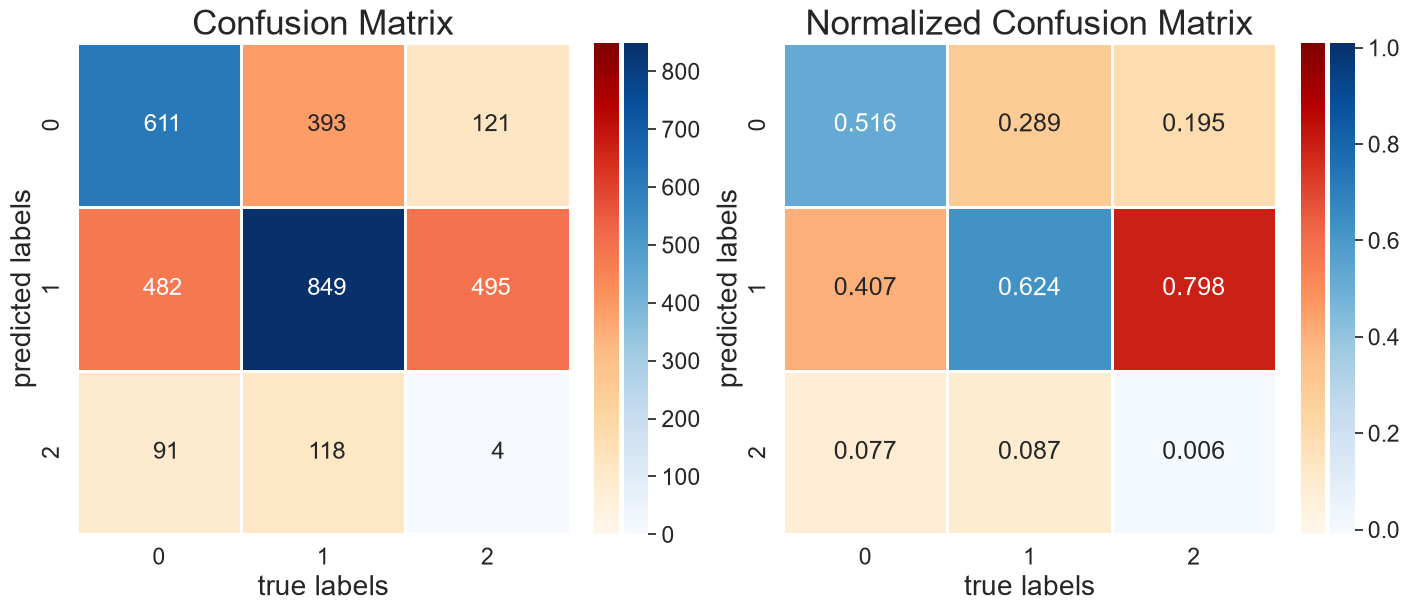

Balanced Accuracy:  38.23 %


In [117]:
classlabels = y_test

if isinstance(model_curr, xEEGNetSCC):
    scores = get_performances(
        loader2eval=testloader_scc,
        Model=model_curr,
        device=device,
        nb_classes=nb_classes,
        return_scores=True,
        verbose=verbose,
        plot_confusion=True,
        class_labels=classlabels,
    )
else:
    scores = get_performances(
        loader2eval=testloader,
        Model=model_curr,
        device=device,
        nb_classes=nb_classes,
        return_scores=True,
        verbose=verbose,
        plot_confusion=True,
        class_labels=classlabels,
    )
print(f"Balanced Accuracy: {scores['accuracy_weighted'] * 100: .2f} %")

#### shallow net 2


In [ ]:
if False:
    loss_summary = train_model(
        model=shallow_net_2,
        train_dataloader=trainloader,
        epochs=30,
        optimizer=optimizer,
        loss_func=lossFnc,
        lr_scheduler=scheduler,
        EarlyStopper=earlystop,
        validation_dataloader=valloader,
        validation_loss_func=lossVal,
        validation_loss_args=validation_loss_args,
        verbose=verbose,
        device=device,
        return_loss_info=True,
    )

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    shallow_net = shallow_net.to(device)

    # cast from torch.cuda.FloatTensor to torch.FloatTensor
    # x_train_eeg = torch.Tensor(x_train)
    x_train = x_train.to(device)
    y_train_out = shallow_net(x_train)
    y_train_pred = torch.argmax(y_train_out, dim=1).detach().cpu().numpy()

    print("ShallowNet 2 performance on training set:")
    get_performances_metrics(y_train, y_train_pred)

## Scores


           |-----------------------------------------|
           |                SCORE SUMMARY            |
           |-----------------------------------------|
           |  Accuracy score:                 0.167  |
           |  Accuracy score weighted:        0.167  |
           |-----------------------------------------|
           |  Precision score micro:          0.167  |
           |  Precision score macro:          0.083  |
           |  Precision score weighted:       0.083  |
           |-----------------------------------------|
           |  Recall score micro:             0.167  |
           |  Recall score macro:             0.167  |
           |  Recall score weighted:          0.167  |
           |-----------------------------------------|
           |  F1-score micro:                 0.167  |
           |  F1-score macro:                 0.111  |
           |  F1-score weighted:              0.111  |
           |-----------------------------------------|
          

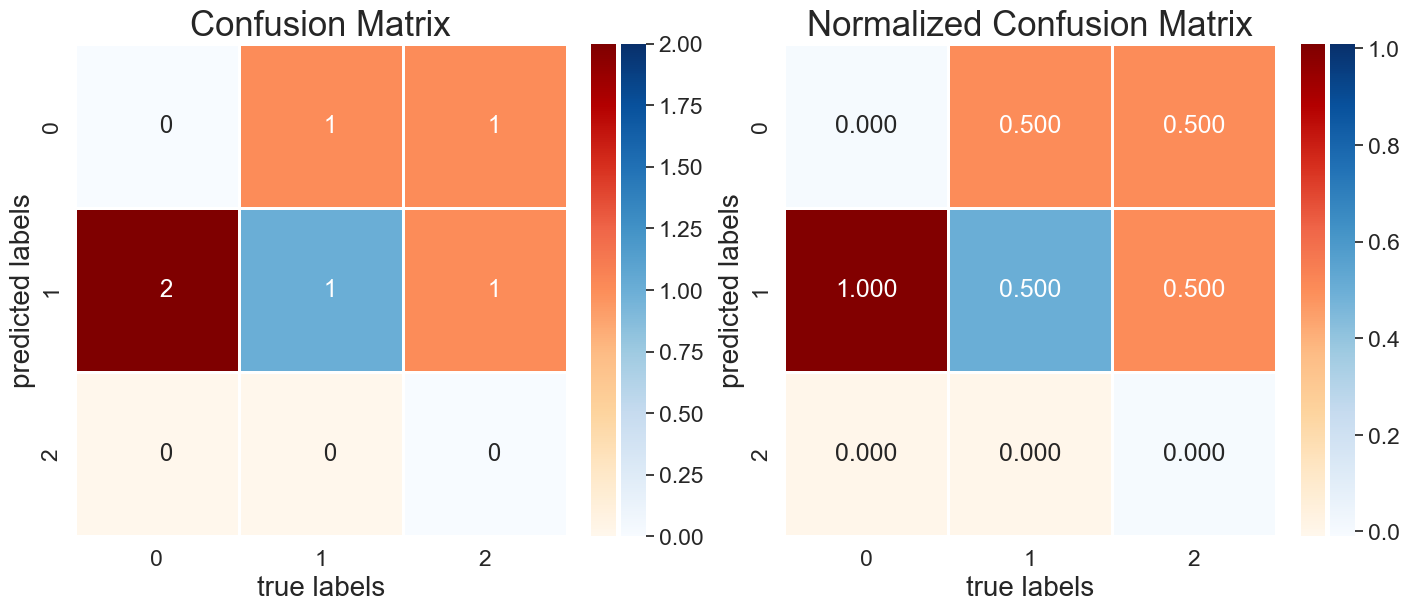

Balanced Accuracy:  16.67 %


In [ ]:
classlabels = y_test

scores = get_performances(
    loader2eval=testloader,
    Model=model_curr,
    device=device,
    nb_classes=nb_classes,
    return_scores=True,
    verbose=verbose,
    plot_confusion=True,
    class_labels=classlabels,
)
print(f"Balanced Accuracy: {scores['accuracy_weighted'] * 100: .2f} %")

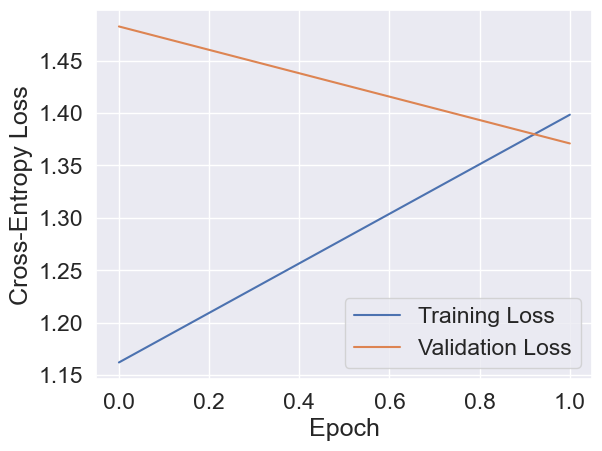

In [178]:
training_loss_curve = []
validation_loss_curve = []
# Iterate through the dictionary, filtering out entries with None values
for key, (train_loss, val_loss) in loss_summary.items():
    if train_loss is not None and val_loss is not None:
        training_loss_curve.append(train_loss)
        validation_loss_curve.append(val_loss)

scores["training_loss_curve"] = training_loss_curve
scores["validation_loss_curve"] = validation_loss_curve

plt.plot(training_loss_curve, label="Training Loss")
plt.plot(validation_loss_curve, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.show()

## Save the model


In [179]:
model_name = "xeeg_test_mini.pt"

dir_models = os.path.join(dir_shallownetXAI, "newmodels") + sep
model_path = os.path.join(dir_models, model_name)

dirResults = os.path.join(dir_shallownetXAI, "new_results") + sep
results_path = os.path.join(dirResults, f"{model_name[:-3]}_results.pickle")

In [180]:
results_path

'..\\..\\backend\\experiments_xeegnet\\shallownetXAI_main\\new_results\\xeeg_test_mini_results.pickle'

In [ ]:
print("model dir:", dir_models, os.path.isdir(dir_models))
print("model path:", model_path, os.path.abspath(model_path))
print("results dir:", dirResults, os.path.isdir(dirResults))
print(
    "results path:",
    results_path,
    os.path.abspath(results_path),
    os.path.exists(results_path),
)

model dir: ..\..\backend\experiments_xeegnet\shallownetXAI_main\newmodels\ True
model path: ..\..\backend\experiments_xeegnet\shallownetXAI_main\newmodels\xeeg_test_mini.pt c:\Users\grabn\Documents\CGV_2024\xeegVis_alll\all-in-on-eeg\backend\experiments_xeegnet\shallownetXAI_main\newmodels\xeeg_test_mini.pt
results dir: ..\..\backend\experiments_xeegnet\shallownetXAI_main\new_results\ True
results path: ..\..\backend\experiments_xeegnet\shallownetXAI_main\new_results\xeeg_test_mini_results.pickle c:\Users\grabn\Documents\CGV_2024\xeegVis_alll\all-in-on-eeg\backend\experiments_xeegnet\shallownetXAI_main\new_results\xeeg_test_mini_results.pickle True


In [183]:
save_model = False

if save_model:
    # Save the model
    model_curr.eval()
    model_curr.to(device="cpu")
    torch.save(model_curr.state_dict(), model_path)

    # Save the scores
    with open(results_path, "wb") as handle:
        pickle.dump(scores, handle, protocol=pickle.HIGHEST_PROTOCOL)